# Team 7 · Monday, part 3: better features for search (round 2)

Round 1 (`improvements_final.ipynb`) found that a **frozen pretrained network in front** of a small autoencoder triples search quality (precision@5 0.14 → 0.41), while regularisers and more pixels barely matter. The matches still follow the **scene** (kitchens, garden walls) as much as the material.

Round 2 tests four ideas, all **without MINC labels** and all with the same small feature autoencoder (512/768/2,080 → **32** numbers, denoising + weight decay, the best round-1 setting):

| Idea | What changes | Why it might help |
|---|---|---|
| **Cosine distance** | compare the *direction* of codes instead of Euclidean distance | the standard for CNN features: the pattern matters, not how strongly it fires |
| **Centre crop** | the network sees only the middle half of the patch, enlarged to 224 px | MINC labels describe the centre; less scene, more surface |
| **Texture (Gram) features** | which ResNet-18 filters (layer 3) fire *together*, ignoring where | the style-transfer trick: describes texture, throws away layout |
| **DINOv2-small** | a stronger, self-supervised backbone instead of ResNet-18 | trained without labels to find similar images; very good for retrieval |
| **Test-time augmentation** | average DINOv2 features of the patch, its mirror image and its centre crop | steadier codes |

**Needs:** the parquet files in `data/minc-2500/data/`. The first run extracts all features once (cached in `data/`, git-ignored). ResNet-18 and DINOv2-small weights are downloaded on first use (45 MB + 88 MB).

In [1]:
import io
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from PIL import Image
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import ResNet18_Weights, resnet18
from transformers import AutoModel

AE_DIR = Path("..")
DATA_DIR = AE_DIR / ".." / "data"
MINC_DIR = DATA_DIR / "minc-2500" / "data"
FIG_DIR = AE_DIR / "figures"
RANDOM_STATE = 42
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
pd.set_option("display.float_format", "{:,.3f}".format)
print(f"PyTorch {torch.__version__}, device: {DEVICE}")


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

/Users/snehashenoy/Downloads/group7_day1_assigment/hackathon-team7-MINC_2500_material_patches/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1, device: mps


# 1. Feature extraction (one pass over all patches)

For every patch: the centre square, resized to 224 px (**full**), and the middle half resized to 224 px (**centre**). Then:

- **ResNet-18** on full and centre: the 512 pooled features (as in round 1).
- **Gram texture** from ResNet-18 layer 3 (256 channels × 14 × 14 positions): a fixed random projection to 64 channels, then the 64 × 64 matrix of "which channels fire together", averaged over all positions. Its upper triangle gives **2,080 numbers**, with signed square root and length normalisation (the usual recipe for these features).
- **DINOv2-small** on full, mirrored full, and centre: the class token + the mean of the patch tokens (384 + 384 = **768 numbers**).

In [2]:
ALL_CLASSES = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather",
               "metal", "mirror", "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky",
               "stone", "tile", "wallpaper", "water", "wood"]
BUILDING = ["brick", "carpet", "ceramic", "glass", "metal", "mirror", "painted", "plastic",
            "polishedstone", "stone", "tile", "wallpaper", "wood"]
BUILDING_IDS = [ALL_CLASSES.index(c) for c in BUILDING]
OTHER_IDS = [i for i, c in enumerate(ALL_CLASSES) if c not in BUILDING]
remap = {orig: new for new, orig in enumerate(BUILDING_IDS)}
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def centre_square(image, fraction=1.0):
    image = image.convert("RGB")
    w, h = image.size
    side = int(min(w, h) * fraction)
    left, top = (w - side) // 2, (h - side) // 2
    return image.crop((left, top, left + side, top + side))


resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).eval().to(DEVICE)
dino = AutoModel.from_pretrained("facebook/dinov2-small").eval().to(DEVICE)
G_CH = 64
projection = torch.linalg.qr(torch.randn(256, 256, generator=torch.Generator().manual_seed(RANDOM_STATE)))[0][:, :G_CH].to(DEVICE)
triu = torch.triu_indices(G_CH, G_CH)


@torch.no_grad()
def resnet_pass(x):
    # -> pooled features (B, 512) and Gram texture (B, 2080)
    r = resnet
    l3 = r.layer3(r.layer2(r.layer1(r.maxpool(r.relu(r.bn1(r.conv1(x)))))))       # (B, 256, 14, 14)
    pooled = torch.flatten(r.avgpool(r.layer4(l3)), 1)
    f = torch.einsum("bchw,cd->bdhw", l3, projection).flatten(2)                   # (B, 64, 196)
    gram = (f @ f.transpose(1, 2) / f.shape[2])[:, triu[0], triu[1]]               # (B, 2080)
    gram = torch.sign(gram) * gram.abs().sqrt()
    gram = gram / gram.norm(dim=1, keepdim=True)
    return pooled.cpu().numpy(), gram.cpu().numpy()


@torch.no_grad()
def dino_pass(x):
    h = dino(pixel_values=x).last_hidden_state                                     # (B, 1 + 256, 384)
    return torch.cat([h[:, 0], h[:, 1:].mean(1)], dim=1).cpu().numpy()


def to_input(batch_u8):
    x = torch.from_numpy(np.stack(batch_u8)).permute(0, 3, 1, 2).float().div(255)
    return ((x - MEAN) / STD).to(DEVICE)


def extract(split, label_ids, name):
    cache = DATA_DIR / f"minc_round2_{name}.npz"
    if cache.exists():
        d = np.load(cache)
        return {k: d[k] for k in d.files}
    start = time.time()
    files = sorted(MINC_DIR.glob(f"{split}-*.parquet"))
    df = (pl.scan_parquet(files)
          .select(pl.col("image").struct.field("bytes").alias("bytes"), pl.col("label"))
          .filter(pl.col("label").is_in(label_ids)).collect())
    out = {k: [] for k in ["r18_full", "r18_centre", "gram", "dino_full", "dino_flip", "dino_centre"]}
    full, centre = [], []

    def flush():
        xf, xc = to_input(full), to_input(centre)
        pooled, gram = resnet_pass(xf)
        out["r18_full"].append(pooled); out["gram"].append(gram)
        out["r18_centre"].append(resnet_pass(xc)[0])
        out["dino_full"].append(dino_pass(xf))
        out["dino_flip"].append(dino_pass(xf.flip(3)))
        out["dino_centre"].append(dino_pass(xc))

    for b in df["bytes"]:
        square = centre_square(Image.open(io.BytesIO(b)))
        full.append(np.asarray(square.resize((224, 224), Image.BILINEAR)))
        centre.append(np.asarray(centre_square(square, 0.5).resize((224, 224), Image.BILINEAR)))
        if len(full) == 128:
            flush(); full, centre = [], []
    if full:
        flush()
    result = {k: np.concatenate(v).astype(np.float32) for k, v in out.items()}
    result["y"] = df["label"].to_numpy()
    np.savez(cache, **result)
    print(f"{name}: {len(df):,} patches in {time.time() - start:.0f} s -> {cache.name}")
    return result


raw = {name: extract(split, ids, name) for split, ids, name in [
    ("train", BUILDING_IDS, "train"), ("validation", BUILDING_IDS, "val"),
    ("test", BUILDING_IDS, "test"), ("test", OTHER_IDS, "test_other")]}

# Feature sets to compare (test-time augmentation = average of several views)
FEATURE_SETS = {
    "ResNet-18, full patch (round 1)": lambda d: d["r18_full"],
    "ResNet-18, centre crop": lambda d: d["r18_centre"],
    "ResNet-18 Gram texture (layer 3)": lambda d: d["gram"],
    "DINOv2-small, full patch": lambda d: d["dino_full"],
    "DINOv2-small, centre crop": lambda d: d["dino_centre"],
    "DINOv2-small, TTA (full + mirror)": lambda d: (d["dino_full"] + d["dino_flip"]) / 2,
    "DINOv2-small, TTA (full + mirror + centre)": lambda d: (d["dino_full"] + d["dino_flip"] + d["dino_centre"]) / 3,
}
y_train = np.array([remap[v] for v in raw["train"]["y"]])
y_test = np.array([remap[v] for v in raw["test"]["y"]])
img64 = {n: np.load(DATA_DIR / f"minc64_{n}.npz")["X"] for n in ["train", "test"]}
assert (np.load(DATA_DIR / "minc64_train.npz")["y"] == raw["train"]["y"]).all()
print({k: v.shape for k, v in raw["train"].items()})

W1116 22:46:29.740000 98184 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.



Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 223/223 [00:00<00:00, 11247.89it/s]

train: 27,625 patches in 528 s -> minc_round2_train.npz


val: 1,625 patches in 30 s -> minc_round2_val.npz


test: 3,250 patches in 60 s -> minc_round2_test.npz


test_other: 2,500 patches in 47 s -> minc_round2_test_other.npz
{'r18_full': (27625, 512), 'r18_centre': (27625, 512), 'gram': (27625, 2080), 'dino_full': (27625, 768), 'dino_flip': (27625, 768), 'dino_centre': (27625, 768), 'y': (27625,)}


# 2. The feature autoencoder and the two distances

The same `FeatureAE` as round 1 (input → 256 → **32** → 256 → input), trained with the best round-1 regularisers: **denoising** (noise 0.5 on the standardised input) and **weight decay** 1e-4, 30 epochs.

For every feature set we measure precision@5 four ways: on the raw features and on the 32-number code, each with **Euclidean** and **cosine** distance. Cosine = Euclidean distance after scaling every vector to length 1, so the server only needs one extra line.

In [3]:
class FeatureAE(nn.Module):
    def __init__(self, n_in, latent_dim=32, hidden=256):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n_in))

    def forward(self, x):
        return self.decoder(self.encoder(x))


def train_feature_ae(F_train, epochs=30, noise_std=0.5, weight_decay=1e-4, batch_size=256, lr=1e-3):
    torch.manual_seed(RANDOM_STATE)
    model = FeatureAE(F_train.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(torch.from_numpy(F_train)), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(RANDOM_STATE))
    for _ in range(epochs):
        model.train()
        for (x,) in loader:
            x = x.to(DEVICE)
            loss = nn.functional.mse_loss(model(x + noise_std * torch.randn_like(x)), x)
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()


@torch.no_grad()
def encode_and_error(model, F):
    x = torch.from_numpy(F).to(DEVICE)
    code = model.encoder(x)
    return code.cpu().numpy(), ((model.decoder(code) - x) ** 2).mean(1).cpu().numpy()


def unit(Z):
    return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-9)


def precision_at_k(Zg, yg, Zq, yq, k=5):
    _, idx = NearestNeighbors(n_neighbors=k).fit(Zg).kneighbors(Zq)
    hits = yg[idx] == yq[:, None]
    return hits.mean(), hits.mean(axis=1)


rows, results = [], {}
for name, get in FEATURE_SETS.items():
    start = time.time()
    F = {s: get(raw[s]) for s in raw}
    mu, sd = F["train"].mean(0), F["train"].std(0) + 1e-6           # standardise with TRAINING statistics
    Fs = {s: ((F[s] - mu) / sd).astype(np.float32) for s in F}
    model = train_feature_ae(Fs["train"])
    Z, err = {}, {}
    for s in Fs:
        Z[s], err[s] = encode_and_error(model, Fs[s])
    p_raw_e, _ = precision_at_k(Fs["train"], y_train, Fs["test"], y_test)
    p_raw_c, _ = precision_at_k(unit(Fs["train"]), y_train, unit(Fs["test"]), y_test)
    p_ae_e, _ = precision_at_k(Z["train"], y_train, Z["test"], y_test)
    p_ae_c, per_query = precision_at_k(unit(Z["train"]), y_train, unit(Z["test"]), y_test)
    auc = roc_auc_score(np.r_[np.zeros(len(err["test"])), np.ones(len(err["test_other"]))],
                        np.r_[err["test"], err["test_other"]])
    results[name] = {"Z": Z, "per_query": per_query}
    rows.append({"features": name, "numbers in": F["train"].shape[1],
                 "raw, Euclidean": p_raw_e, "raw, cosine": p_raw_c,
                 "AE 32, Euclidean": p_ae_e, "AE 32, cosine": p_ae_c, "unusual AUC": auc})
    print(f"{name:45s} AE 32: Euclidean {p_ae_e:.3f}  cosine {p_ae_c:.3f}  | raw cosine {p_raw_c:.3f}  "
          f"| AUC {auc:.3f}  ({time.time() - start:.0f} s)")

ResNet-18, full patch (round 1)               AE 32: Euclidean 0.414  cosine 0.439  | raw cosine 0.460  | AUC 0.673  (11 s)


ResNet-18, centre crop                        AE 32: Euclidean 0.448  cosine 0.472  | raw cosine 0.487  | AUC 0.706  (10 s)


ResNet-18 Gram texture (layer 3)              AE 32: Euclidean 0.338  cosine 0.363  | raw cosine 0.385  | AUC 0.589  (13 s)


DINOv2-small, full patch                      AE 32: Euclidean 0.562  cosine 0.582  | raw cosine 0.596  | AUC 0.707  (11 s)


DINOv2-small, centre crop                     AE 32: Euclidean 0.631  cosine 0.647  | raw cosine 0.661  | AUC 0.818  (11 s)


DINOv2-small, TTA (full + mirror)             AE 32: Euclidean 0.575  cosine 0.593  | raw cosine 0.602  | AUC 0.709  (10 s)


DINOv2-small, TTA (full + mirror + centre)    AE 32: Euclidean 0.641  cosine 0.652  | raw cosine 0.664  | AUC 0.767  (10 s)


# 3. Results

In [4]:
table = pd.DataFrame(rows).set_index("features")
table.to_csv(AE_DIR / "results_round2.csv")
table.sort_values("AE 32, cosine", ascending=False)

,numbers in,"raw, Euclidean","raw, cosine","AE 32, Euclidean","AE 32, cosine",unusual AUC
features,,,,,,
"DINOv2-small, TTA (full + mirror + centre)",768,0.653,0.664,0.641,0.652,0.767
"DINOv2-small, centre crop",768,0.647,0.661,0.631,0.647,0.818
"DINOv2-small, TTA (full + mirror)",768,0.585,0.602,0.575,0.593,0.709
"DINOv2-small, full patch",768,0.580,0.596,0.562,0.582,0.707
"ResNet-18, centre crop",512,0.452,0.487,0.448,0.472,0.706
"ResNet-18, full patch (round 1)",512,0.424,0.460,0.414,0.439,0.673
ResNet-18 Gram texture (layer 3),2080,0.357,0.385,0.338,0.363,0.589


Figure saved to ../figures/12_round2_precision.png


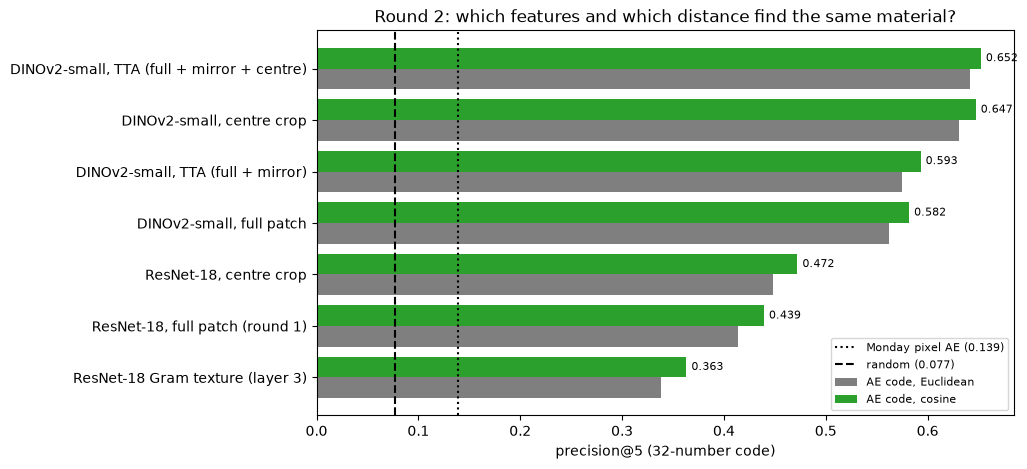

In [5]:
t = table.sort_values("AE 32, cosine")
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(t))
ax.barh(y - 0.2, t["AE 32, Euclidean"], height=0.4, label="AE code, Euclidean", color="tab:gray")
ax.barh(y + 0.2, t["AE 32, cosine"], height=0.4, label="AE code, cosine", color="tab:green")
for i, v in enumerate(t["AE 32, cosine"]):
    ax.text(v + 0.005, i + 0.2, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(y, t.index)
ax.axvline(0.139, color="black", linestyle=":", label="Monday pixel AE (0.139)")
ax.axvline(1 / 13, color="black", linestyle="--", label="random (0.077)")
ax.set_xlabel("precision@5 (32-number code)")
ax.set_title("Round 2: which features and which distance find the same material?")
ax.legend(loc="lower right", fontsize=8)
save_fig("12_round2_precision")
plt.show()

best: DINOv2-small, TTA (full + mirror + centre)


Figure saved to ../figures/13_round2_per_material.png


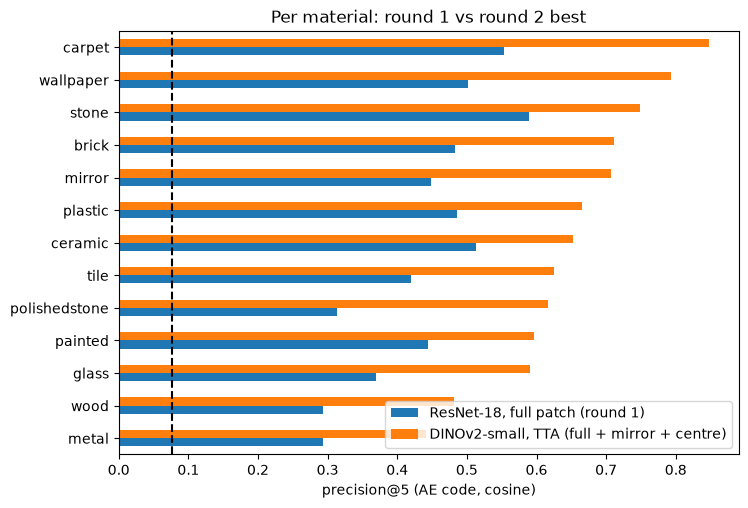

,brick,carpet,ceramic,glass,metal,mirror,painted,plastic,polishedstone,stone,tile,wallpaper,wood
"ResNet-18, full patch (round 1)",0.483,0.554,0.514,0.370,0.293,0.449,0.445,0.486,0.313,0.590,0.420,0.502,0.294
"DINOv2-small, TTA (full + mirror + centre)",0.712,0.848,0.653,0.590,0.442,0.707,0.597,0.666,0.617,0.748,0.625,0.794,0.481


In [6]:
BEST = table["AE 32, cosine"].idxmax()
ROUND1 = "ResNet-18, full patch (round 1)"
print("best:", BEST)
per = pd.DataFrame({n: pd.Series(results[n]["per_query"]).groupby(y_test).mean().set_axis(BUILDING)
                    for n in [ROUND1, BEST]})
ax = per.sort_values(BEST).plot.barh(figsize=(8, 5.5))
ax.axvline(1 / 13, color="black", linestyle="--")
ax.set_xlabel("precision@5 (AE code, cosine)"); ax.set_title("Per material: round 1 vs round 2 best")
save_fig("13_round2_per_material")
plt.show()
per.T

Figure saved to ../figures/14_round2_similarity.png


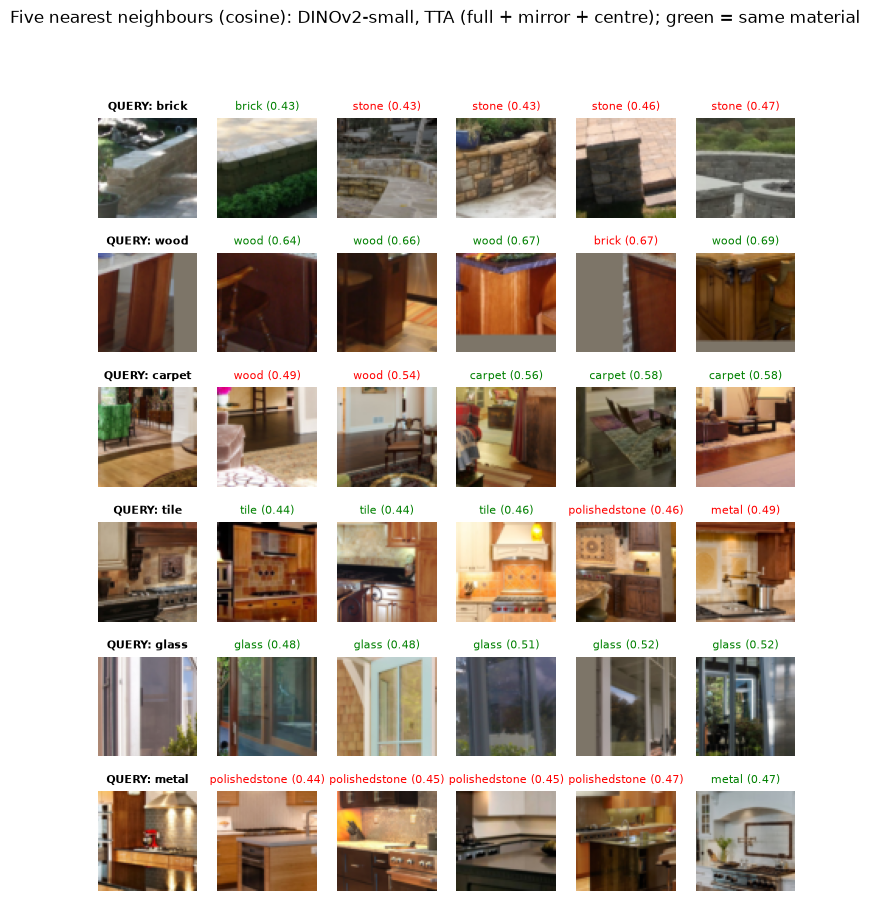

In [7]:
Z = results[BEST]["Z"]
index = NearestNeighbors(n_neighbors=5).fit(unit(Z["train"]))
SHOW = ["brick", "wood", "carpet", "tile", "glass", "metal"]
queries = [int(np.flatnonzero(y_test == BUILDING.index(m))[3]) for m in SHOW]
dist, nbr = index.kneighbors(unit(Z["test"][queries]))
fig, axes = plt.subplots(len(SHOW), 6, figsize=(9, 1.7 * len(SHOW)))
for r, q in enumerate(queries):
    axes[r, 0].imshow(img64["test"][q]); axes[r, 0].set_title(f"QUERY: {BUILDING[y_test[q]]}", fontsize=8, fontweight="bold")
    for c in range(5):
        i = nbr[r, c]
        axes[r, c + 1].imshow(img64["train"][i])
        axes[r, c + 1].set_title(f"{BUILDING[y_train[i]]} ({dist[r, c]:.2f})", fontsize=8,
                                 color="green" if y_train[i] == y_test[q] else "red")
    for a in axes[r]:
        a.axis("off")
plt.suptitle(f"Five nearest neighbours (cosine): {BEST}; green = same material")
save_fig("14_round2_similarity")
plt.show()

# 4. What we conclude

Measured with precision@5 on the 3,250 building test patches (random = 0.077).

**How much does cosine distance add? Is it worth the one extra line on the server?**
- **It helps every feature set**, by **+0.011 to +0.025** on the 32-number AE code: ResNet full 0.414 → 0.439, ResNet centre 0.448 → 0.472, Gram 0.338 → 0.363, DINOv2 full 0.562 → 0.582, DINOv2 centre 0.631 → 0.647, TTA 0.641 → 0.652.
- The gain is smaller for stronger features (DINOv2), but it never hurts.
- **Yes, keep it.** It costs one line (scale each code to length 1, before indexing the gallery and before each query), and no extra time or memory.

**Does the centre crop help ResNet and DINOv2? What does that say about MINC patches?**
- **Yes, clearly, for both.** ResNet: 0.439 → **0.472** (+0.033). DINOv2: 0.582 → **0.647** (+0.065). The unusual score improves even more: DINOv2's AUC goes from 0.707 to **0.818**, the best in the whole project.
- This confirms the scene problem: a MINC patch shows a whole room or facade, but its label only describes the **centre**. The full patch mixes in the surroundings (furniture, sky, other materials), so the matches follow the scene. Cropping to the centre makes the network look at the **surface**.
- For the app: ask users to photograph the surface **close up**, or crop to the centre on the server.

**Do Gram texture features beat the pooled ResNet features?**
- **No, they are the worst feature set:** 0.363 against 0.439 for the pooled ResNet features (cosine, AE 32), and AUC 0.589 against 0.673.
- Gram features describe "which filters fire together" and throw away all layout. That suits style transfer, but layer 3 of ResNet-18 at 14 × 14 positions is too low-level for materials: it describes small-scale texture, and many materials share it (smooth plaster ≈ smooth plastic ≈ painted wall). Pooled features keep higher-level information about the material, which the 2,080 Gram numbers lack.

**How much better is DINOv2-small than ResNet-18? Is TTA worth 3 runs of the network?**
- **DINOv2 is much better.** On the same input it beats ResNet by about **+0.14 to +0.18**: full patch 0.439 → 0.582, centre crop 0.472 → 0.647. The best DINOv2 setup is **4.7× better than our Monday baseline (0.14)** and **8.4× random**.
- Per material, the best setup improves on round 1 for every material: carpet 0.55 → 0.85, wallpaper 0.50 → 0.79, brick 0.48 → 0.71, polished stone 0.31 → 0.62, mirror 0.45 → 0.71. **Metal (0.44) and wood (0.48) are still the weakest.**
- **TTA is not worth it.** Full + mirror + centre gives 0.652, only **+0.005** over the centre crop alone (0.647), which is within the noise. Its unusual AUC is **worse** (0.767 vs 0.818), because it mixes the full patch back in. It also runs the network **3 times per photo**. Full + mirror alone (0.593) adds little over the full patch (0.582).
- **Our choice: DINOv2-small, centre crop → AE 32 → cosine.** It ties with the best search and has the best unusual score, with one network run per photo.

**Deployment cost: ResNet-18 ≈ 45 MB, DINOv2-small ≈ 88 MB as ONNX. Render free server: 512 MB RAM, slow CPU.**
- DINOv2-small (22 M parameters) should fit: about 88 MB on disk and roughly 200–300 MB in RAM with ONNX Runtime, under the 512 MB limit. One 224 px image takes about 0.5–1 s on a slow CPU, which is acceptable for an app that handles one photo at a time.
- Risks: a slow cold start (download from Hugging Face plus model load), and little memory left for other work. Keep one model in memory, one request at a time, no TTA.
- **Test this on Render on Tuesday** before we commit. If memory runs out, ResNet-18 + centre crop (0.472, 45 MB) is the fallback.
- The gain (0.47 → 0.65) is large enough to justify the bigger model.

**Honesty note:** ResNet-18 was trained **with ImageNet labels** (objects, not materials). DINOv2 was trained **without labels** (self-supervised, on 142 million images), so the winning pipeline uses no human labels anywhere: not in DINOv2 and not in our autoencoder. MINC labels are only used to **measure** precision@5. Most of the gain comes from DINOv2's features. Our autoencoder compresses them from 768 to 32 numbers (24×) and costs only about 0.015 in precision@5 (raw cosine 0.661 vs AE 0.647).